In [1]:
import os
import sys

dir_paht = '../../learning/segment_anything/Wide Field Images Cropped/'
sys.path.append(dir_paht)

In [2]:
import torchvision.transforms as T
from PIL import Image
import torch
from torchvision import transforms
from torchvision.utils import draw_segmentation_masks
import torchvision.transforms.functional as F

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import segment_anything
from segment_anything import SamPredictor, sam_model_registry, SamAutomaticMaskGenerator

import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2
from tqdm import trange, tqdm

In [3]:
if torch.cuda.is_available():
    print("Good to go!")
    DEVICE = torch.device("cuda")
else:
    print("Please set GPU via Edit -> Notebook Settings.")
    DEVICE = torch.device("cpu")

Please set GPU via Edit -> Notebook Settings.


In [4]:
sam = sam_model_registry["default"](checkpoint=os.path.join("../../learning/segment_anything/", "sam_vit_h_4b8939.pth"))
sam.to(device=DEVICE)

Sam(
  (image_encoder): ImageEncoderViT(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 1280, kernel_size=(16, 16), stride=(16, 16))
    )
    (blocks): ModuleList(
      (0): Block(
        (norm1): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1280, out_features=3840, bias=True)
          (proj): Linear(in_features=1280, out_features=1280, bias=True)
        )
        (norm2): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (lin1): Linear(in_features=1280, out_features=5120, bias=True)
          (lin2): Linear(in_features=5120, out_features=1280, bias=True)
          (act): GELU(approximate='none')
        )
      )
      (1): Block(
        (norm1): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1280, out_features=3840, bias=True)
          (proj): Linear(in_features=1280, out_features=1280, b

In [5]:
images = [cv2.imread(os.path.join(dir_paht, x)) for x in os.listdir(dir_paht)]
images = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images]

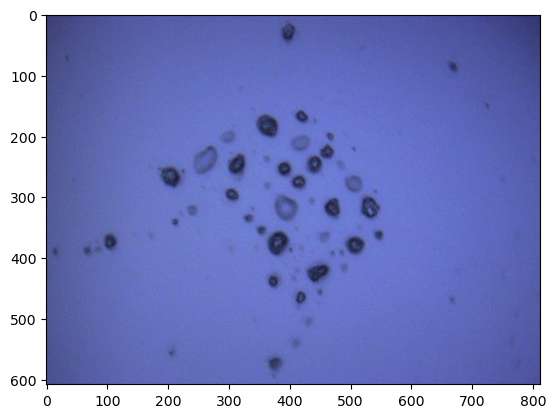

In [6]:
plt.imshow(images[1])

In [7]:
mask_generator = SamAutomaticMaskGenerator(sam)
mask = mask_generator.generate(images[1])

In [79]:
np.random.random((1, 3)).tolist()[0]

[0.09980077474981264, 0.07677236073256877, 0.8278240636001903]

In [88]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = [.5,.5,.5]#np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))

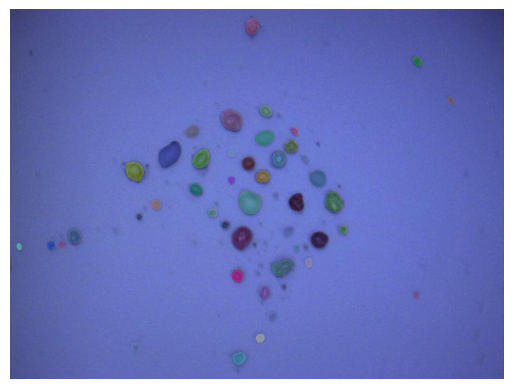

In [10]:
plt.imshow(images[1])
show_anns(mask[1:])
plt.axis('off')
plt.show() 

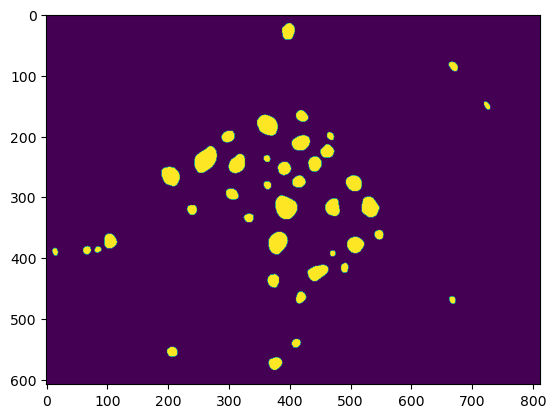

In [11]:
mask_true = cv2.imread('annotation_mask/SegmentationObject/MEC_02_038_OPTIR_quartz_3.png')
mask_1 = np.array([m['segmentation'] for m in mask[1:]]).sum(0)>0
plt.imshow(mask_1)

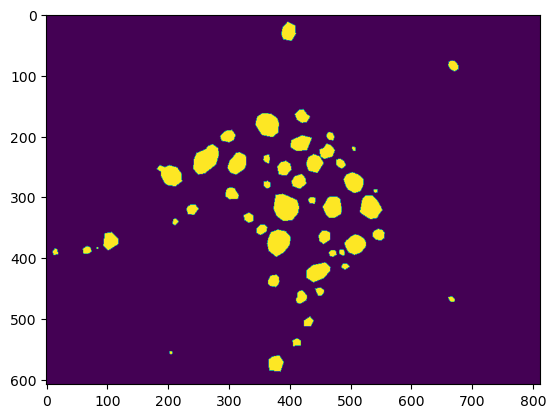

In [13]:
mask_true_f = mask_true.reshape(608 * 812, 3)
particles = np.unique(mask_true_f, axis=0)#[mask_true_f.sum(1) > 0]

mask_true_0 = [[np.any([(mask_true[i,j] == p).all() for p in particles[1:]]) for i in range(608)] for j in range(812)]
mask_true_1 = np.array(mask_true_0).T
plt.imshow(mask_true_1)

In [14]:
iou_1 = np.round(100*np.logical_and(mask_true_1, mask_1).sum() / np.logical_or(mask_true_1, mask_1).sum())
iou_1

70.0

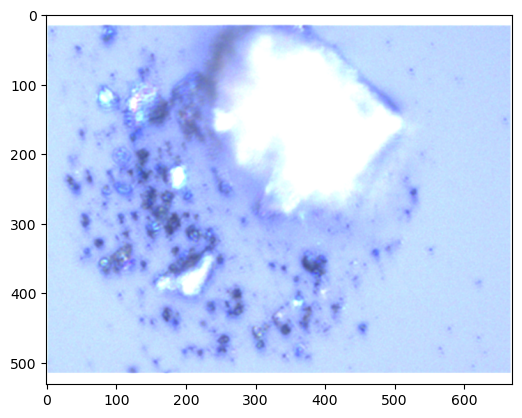

In [28]:
image = cv2.imread('MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# define the alpha and beta
alpha = 0 # Contrast control
beta = 2 # Brightness control

image_1 = cv2.convertScaleAbs(image, alpha, beta)
plt.imshow(image_1)

In [ ]:
# read the input image

# define the contrast and brightness value
contrast = 2. # Contrast control ( 0 to 127)
brightness = 0. # Brightness control (0-100)

# call addWeighted function. use beta = 0 to effectively only

out = cv2.addWeighted( image, contrast, image, 0, brightness)

# display the image with changed contrast and brightness
cv2.imshow('adjusted', out)
cv2.waitKey(0)
cv2.destroyAllWindows()

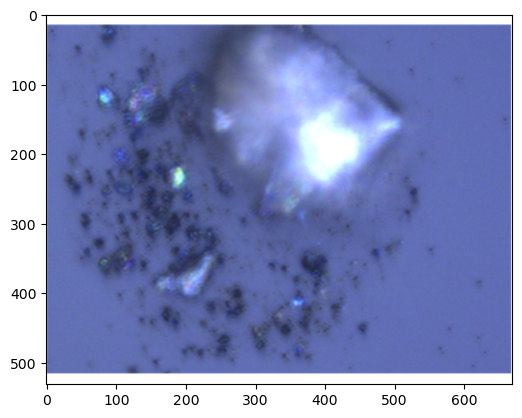

In [142]:
plt.imshow(image)

In [ ]:
mask_generator = SamAutomaticMaskGenerator(sam)
mask = mask_generator.generate(image_1)

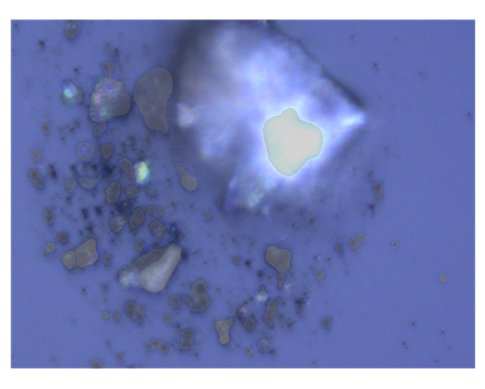

In [89]:
plt.imshow(image)
show_anns(mask[3:])
plt.axis('off')
plt.show() 

In [17]:
len(mask)

74

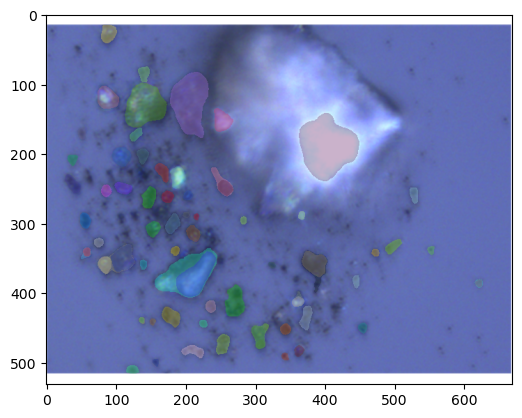

In [23]:
plt.imshow(image)
show_anns(mask[3:])

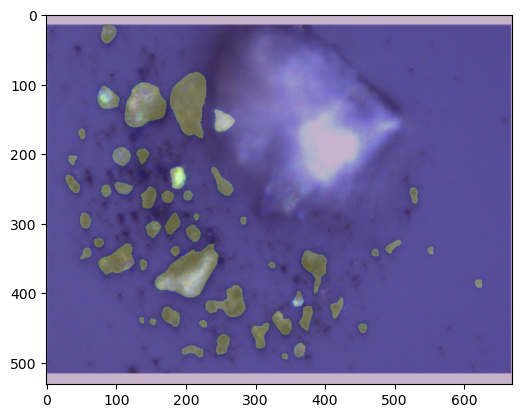

In [14]:
mask_1 = np.array([m['segmentation'] for m in mask[3:]]).sum(0)>0
plt.imshow(image)
plt.imshow(mask_1, alpha=.3)

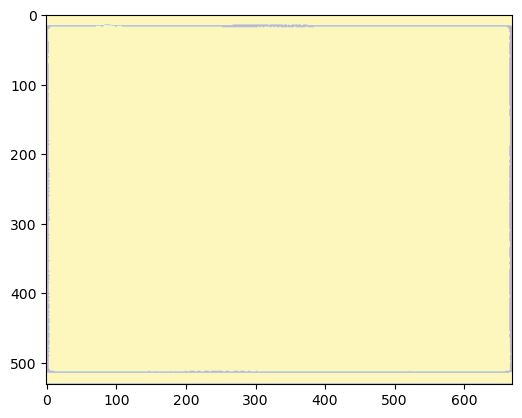

In [25]:
mask_1 = np.array([m['segmentation'] for m in mask[0:]]).sum(0)>0
plt.imshow(mask_1, alpha=.3)

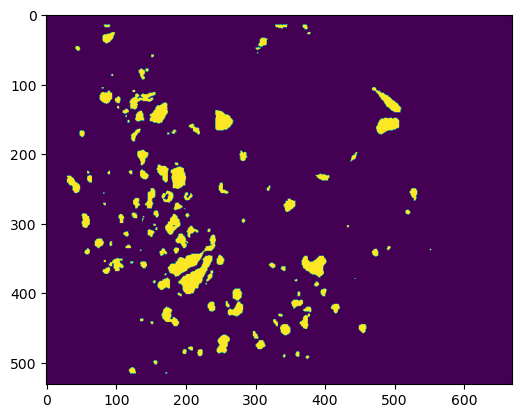

In [53]:
plt.imshow((mask_true[:,:,0]<255)*1)

In [114]:
mask_1

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

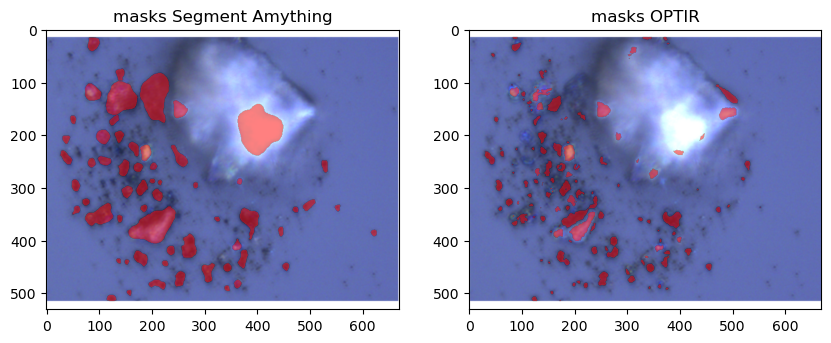

In [123]:
fig, ax = plt.subplots(nrows=1, ncols=2)
fig.set_figheight(10)
fig.set_figwidth(10)

_ = ax[0].imshow(image)
_ = ax[0].imshow(np.concatenate([(mask_1*1)[:,:,None],
 (mask_1*0)[:,:,None],
 (mask_1*0)[:,:,None],
 (mask_1*.5)[:,:,None]],2))
_ = ax[0].title.set_text('masks Segment Amything')

_ = ax[1].imshow(image)
_ = ax[1].imshow(np.concatenate([((mask_true[:,:,0]<255)*1)[:,:,None],
 ((mask_true[:,:,0]<255)*0)[:,:,None],
 ((mask_true[:,:,0]<255)*0)[:,:,None],
 ((mask_true[:,:,0]<255)*.5)[:,:,None]],2))
_ = ax[1].title.set_text('masks OPTIR')

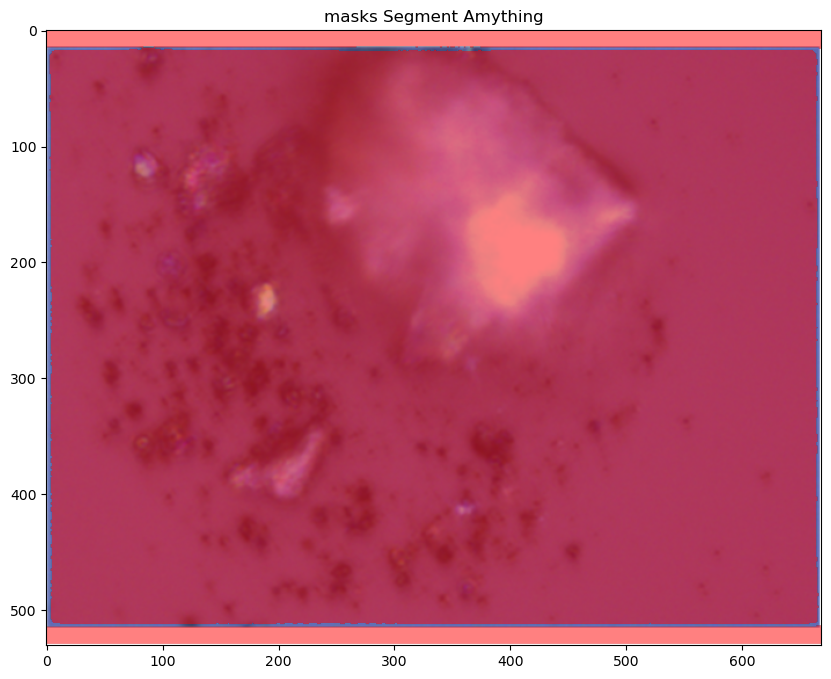

In [20]:
mask_1 = np.array([m['segmentation'] for m in mask]).sum(0)>0

fig, ax = plt.subplots(nrows=1, ncols=1)
fig.set_figheight(10)
fig.set_figwidth(10)

_ = ax.imshow(image)
_ = ax.imshow(np.concatenate([(mask_1*1)[:,:,None],
 (mask_1*0)[:,:,None],
 (mask_1*0)[:,:,None],
 (mask_1*.5)[:,:,None]],2))
_ = ax.title.set_text('masks Segment Amything')

In [19]:
mask_true = cv2.imread('MEC_02_063_FHS_back_Al_slide_03292023_04262023_run2_masks.png')

In [39]:
np.unique(mask_true[:,:,0])

array([128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140,
       141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153,
       154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166,
       167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179,
       180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192,
       193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205,
       206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218,
       219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231,
       232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244,
       245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255], dtype=uint8)